# 17 — Scelta ed estrazione di nuove clip da 1 minuto

1. **Panoramica**: un fotogramma ogni N secondi di un tratto del video, con il tempo scritto sopra, per scegliere a colpo d'occhio dove c'è gioco continuo (inquadratura larga, niente primi piani / replay / pause).
2. **Anteprima**: 6 fotogrammi di un minuto candidato, per controllare prima di tagliare.
3. **Taglio**: estrae le clip scelte in `videos/eventi/`, con controllo di sovrapposizione con le clip già esistenti.

⚠️ **Zona di test del detector della palla** (notebook 16): il 30% finale del video, cioè dal frame 28800 (≈ 16:01) in poi, non è stato usato per addestrare il detector della palla. Le clip **prima** di 16:01 contengono alcuni fotogrammi usati nell'addestramento: si possono usare, ma nella tesi va dichiarato (la cella 4 lo segnala).

In [ ]:
from google.colab import drive; drive.mount('/content/drive')
from pathlib import Path
import cv2, numpy as np, subprocess, shutil, matplotlib.pyplot as plt
ROOT = Path('/content/drive/MyDrive/Tesi_Basket')
SRC = ROOT / 'videos' / 'nba_finals2016_1part.mp4'      # <-- nuovo video (stessa partita, mai visto in addestramento)
OUT_DIR = ROOT / 'videos' / 'eventi'; OUT_DIR.mkdir(parents=True, exist_ok=True)
CLIP_S = 60
W_REF, H_REF, FPS_REF = 1280, 720, 29.97                 # formato delle clip az1-az5

cap = cv2.VideoCapture(str(SRC)); assert cap.isOpened(), f'non trovo {SRC}'
FPS = cap.get(cv2.CAP_PROP_FPS); NF = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)); cap.release()
DUR = NF / FPS
mmss = lambda t: f'{int(t // 60)}:{t % 60:04.1f}'
def to_s(x): return x if isinstance(x, (int, float)) else int(x.split(':')[0]) * 60 + float(x.split(':')[1])

# --- controllo qualità rispetto alle clip az1-az5 ---
print(f'{SRC.name}: {W}x{H} a {FPS:.2f} fps, durata {mmss(DUR)}')
RISCALA = (W, H) != (W_REF, H_REF)
FPS_OK = abs(FPS - FPS_REF) < 0.05
print('risoluzione:', 'OK (1280x720)' if not RISCALA else f'diversa -> le clip verranno riscalate a {W_REF}x{H_REF}')
print('fps:', 'OK (29.97)' if FPS_OK else f'DIVERSI ({FPS:.2f}) -> le clip verranno convertite a 29.97 fps (da dichiarare nella tesi)')

# questo video non è mai stato usato in addestramento: nessuna zona da evitare, nessuna clip già estratta
TEST_S = 0.0
ESISTENTI = {}

Mounted at /content/drive
nba_finals2016_1part.mp4: 1280x720 a 30.00 fps, durata 43:35.4
risoluzione: OK (1280x720)
fps: OK (29.97)


## 1. Panoramica di un tratto del video (un fotogramma ogni `PASSO_S` secondi)

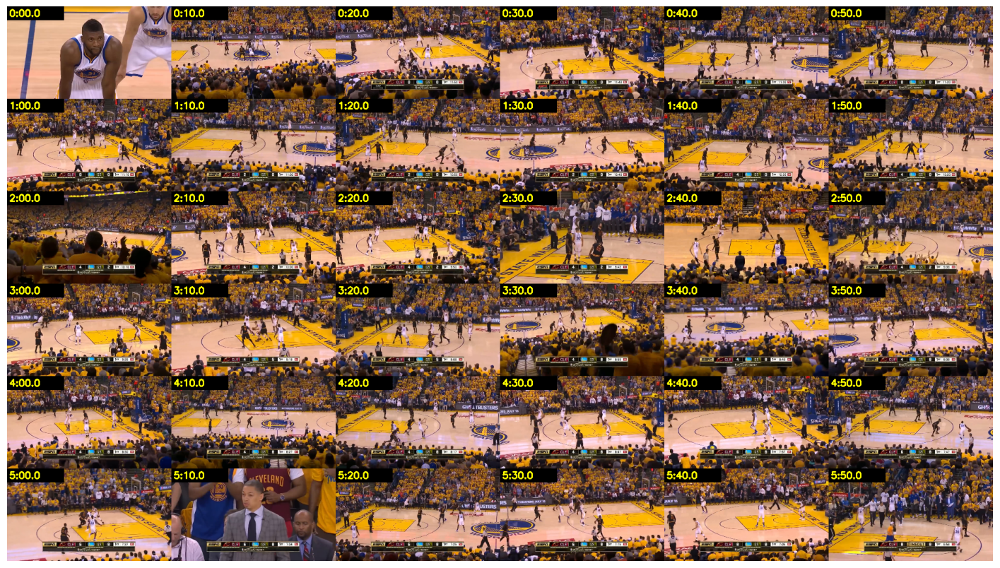

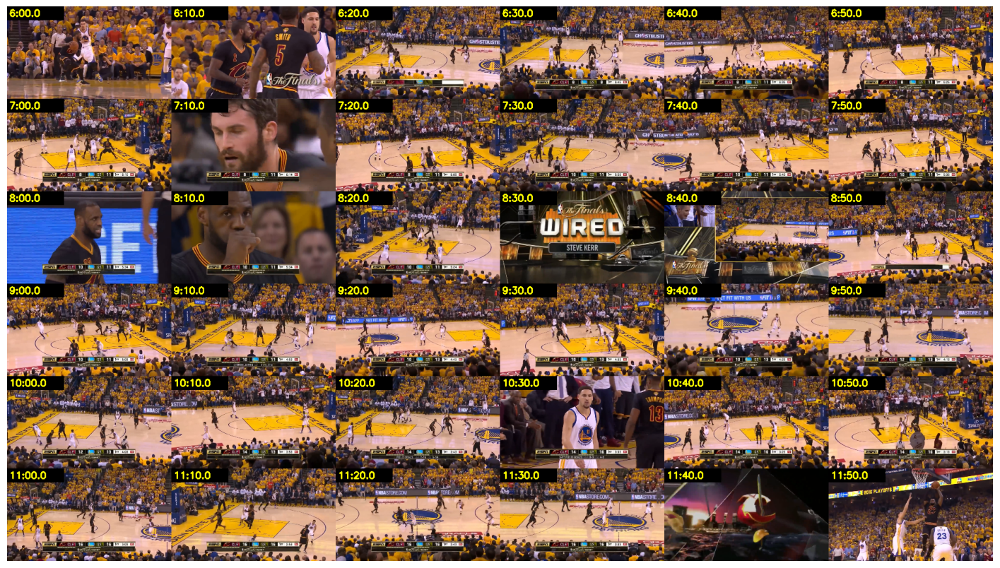

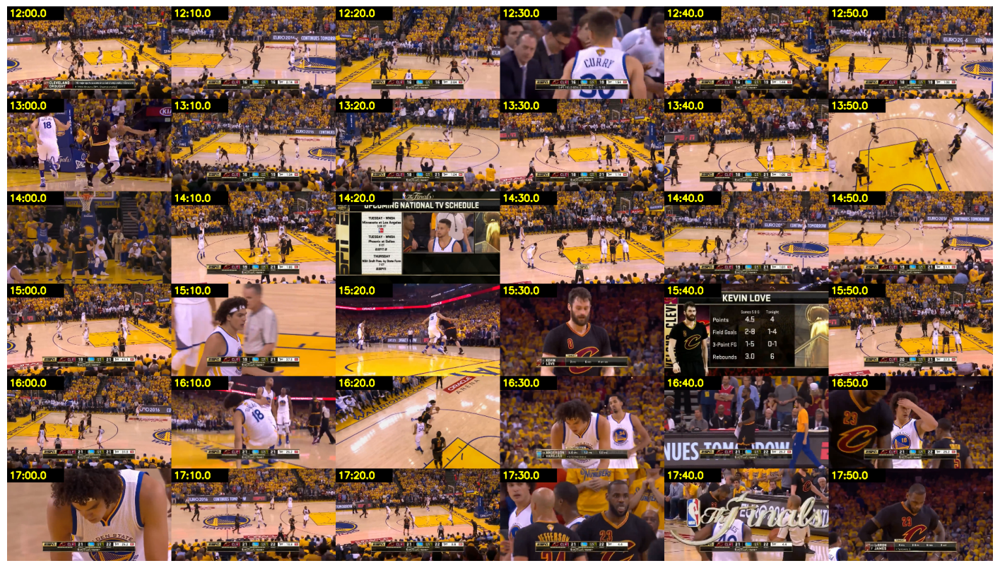

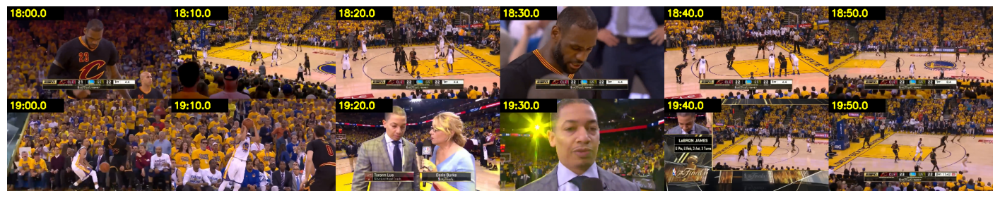

Bordo rosso = tratto già usato in az1-az3. Cerca minuti con inquadratura larga e gioco continuo.


In [ ]:
DA, A = '0:00', '20:00'          # <-- tratto da sfogliare; allarga A se il video è più lungo
PASSO_S = 10
COLONNE = 6

ts = np.arange(to_s(DA), min(to_s(A), DUR), PASSO_S)
cap = cv2.VideoCapture(str(SRC)); thumbs = []
for t in ts:
    cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000); ok, f = cap.read()
    if not ok: continue
    f = cv2.resize(f, (320, 180)); cv2.rectangle(f, (0, 0), (110, 26), (0, 0, 0), -1)
    cv2.putText(f, mmss(t), (4, 19), cv2.FONT_HERSHEY_SIMPLEX, .6, (0, 255, 255), 2)
    if any(a <= t < b for a, b in ESISTENTI.values()): cv2.rectangle(f, (0, 0), (319, 179), (0, 0, 255), 6)   # già usato
    thumbs.append(f)
cap.release()
while len(thumbs) % COLONNE: thumbs.append(np.zeros_like(thumbs[0]))
rows = [np.hstack(thumbs[i:i + COLONNE]) for i in range(0, len(thumbs), COLONNE)]
for i in range(0, len(rows), 6):                                   # a blocchi, per non fare un'immagine enorme
    plt.figure(figsize=(18, 3 * len(rows[i:i + 6]))); plt.imshow(cv2.cvtColor(np.vstack(rows[i:i + 6]), cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()
print('Bordo rosso = tratto già usato in az1-az3. Cerca minuti con inquadratura larga e gioco continuo.')

## 2. Anteprima di un minuto candidato (6 fotogrammi, uno ogni 10 s)

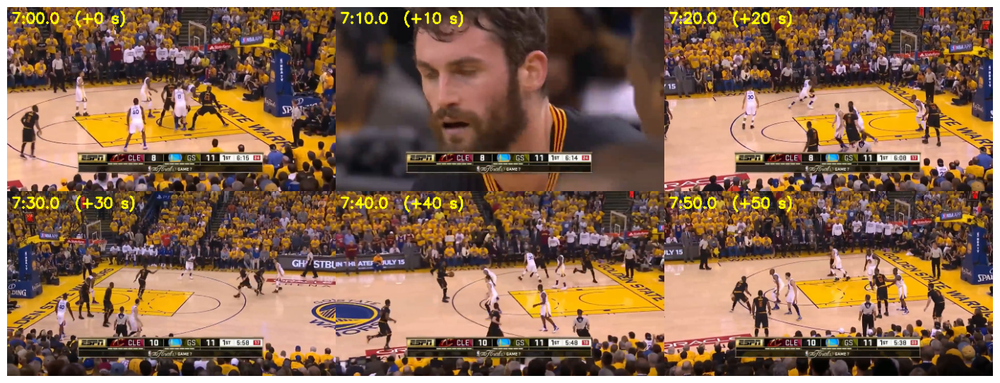

In [ ]:
INIZIO = '7:00'                 # <-- inizio del minuto candidato

t0 = to_s(INIZIO); cap = cv2.VideoCapture(str(SRC)); ims = []
for t in t0 + np.arange(0, CLIP_S, 10):
    cap.set(cv2.CAP_PROP_POS_MSEC, t * 1000); ok, f = cap.read()
    if ok:
        f = cv2.resize(f, (480, 270)); cv2.putText(f, f'{mmss(t)}  (+{t - t0:.0f} s)', (6, 24), cv2.FONT_HERSHEY_SIMPLEX, .7, (0, 255, 255), 2); ims.append(f)
cap.release()
plt.figure(figsize=(18, 7)); plt.imshow(cv2.cvtColor(np.vstack([np.hstack(ims[:3]), np.hstack(ims[3:6])]), cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()

## 3. Taglio delle clip scelte

In [ ]:
TAGLI = [
    ('finals2016_test1', '7:00'),    # <-- inizio scelto
]

assert shutil.which('ffmpeg'), 'ffmpeg mancante'
vf = ['-vf', f'scale={W_REF}:{H_REF}'] if RISCALA else []
rf = [] if FPS_OK else ['-r', '30000/1001']
for nome, inizio in TAGLI:
    a = to_s(inizio); b = a + CLIP_S; dst = OUT_DIR / f'{nome}.mp4'
    over = [k for k, (x, y) in ESISTENTI.items() if a < y and x < b]
    if over: print(f'✗ {nome}: si sovrappone a {over}, scegli un altro inizio'); continue
    if b > DUR: print(f'✗ {nome}: va oltre la fine del video'); continue
    if dst.is_file(): print(f'= {nome}: esiste già ({mmss(a)} - {mmss(b)})'); ESISTENTI[nome] = (a, b); continue
    subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-ss', f'{a:.2f}', '-to', f'{b:.2f}', '-i', str(SRC),
                    *vf, *rf, '-c:v', 'libx264', '-crf', '18', '-an', str(dst)], check=True)
    ESISTENTI[nome] = (a, b)
    c = cv2.VideoCapture(str(dst))
    print(f'✓ {nome}: {mmss(a)} - {mmss(b)} -> {dst.name} | {int(c.get(3))}x{int(c.get(4))} a {c.get(5):.2f} fps, {int(c.get(7))} frame'); c.release()

✓ finals2016_test1: 7:00.0 - 8:00.0 -> finals2016_test1.mp4 | 1280x720 a 30.00 fps, 1800 frame
